> **หมายเหตุ:** outputs เดิมเป็นผลจากโค้ดรุ่นก่อน; rerun หลังสร้าง checkpoint multi-label ใหม่เท่านั้น

# RakForest — Evaluate multi-label audio classifier

ประเมิน checkpoint รุ่น `multilabel-v1` ด้วย test split ที่กันไว้และไม่ใช้เลือกรุ่น Threshold ใช้ค่า 0.5 ที่กำหนดไว้ก่อนประเมิน; ห้ามปรับจาก test. รายงาน precision/recall/F1 แยกคลาส, micro/macro-F1, exact match และข้อผิดพลาด false positive/false negative.

## วิธีทำงานของไฟล์นี้: ประเมินโมเดลบนข้อมูลที่กันไว้

ไฟล์นี้เป็นขั้น **evaluation หลังฝึก** โหลด checkpoint multi-label จาก 03 และตรวจว่า provenance กับ manifest ตรงกันก่อนใช้ เพื่อกันการนำ checkpoint เก่าหรือข้อมูลคนละชุดมาประเมิน

โมเดลให้คะแนน sigmoid แยกตามคลาส แล้วใช้ threshold ที่บันทึกมากับ checkpoint (ค่าเริ่มต้น 0.5) รายงาน macro/micro-F1, exact match, Hamming loss และ precision/recall/F1 รายคลาส พร้อมตัวอย่างคลาสที่พลาด การปรับ threshold ควรทำจาก validation แล้วล็อกค่าก่อนรายงาน test

Test ใช้เฉพาะข้อมูลที่กันไว้ออกจากการฝึกและการเลือก checkpoint; ไม่มี waveform mixing ใน evaluation ถ้า test มีคลิปที่ติดหลายป้ายตาม metadata น้อยหรือไม่มี ผลนี้ยังไม่ยืนยันความสามารถกับเสียงซ้อนจริง ต้องตรวจจำนวนตัวอย่างและหาเสียงจริงที่มีหลายเหตุการณ์ร่วมกันเพิ่มเติม


## 1. ติดตั้ง dependencies

In [1]:
# Install only missing dependencies; avoid upgrading the working environment on every rerun.
import importlib.util, subprocess, sys
required_modules={
    'torch':'torch', 'librosa':'librosa', 'soundfile':'soundfile', 'pandas':'pandas',
    'numpy':'numpy', 'sklearn':'scikit-learn', 'matplotlib':'matplotlib',
    'seaborn':'seaborn', 'tqdm':'tqdm', 'pyarrow':'pyarrow', 'IPython':'ipython'
}
missing_packages=[package for module,package in required_modules.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    print('Installing missing packages:', missing_packages)
    subprocess.check_call([sys.executable,'-m','pip','install',*missing_packages])
else:
    print('All required packages are already installed.')


All required packages are already installed.


## 2. Imports, paths และ device

In [2]:
from pathlib import Path
import json, hashlib, random
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from IPython.display import Audio, display, Markdown
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, classification_report, confusion_matrix
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=='notebooks': PROJECT_ROOT=PROJECT_ROOT.parent
PROCESSED_DIR=PROJECT_ROOT/'data'/'processed'
MODEL_DIR=PROJECT_ROOT/'models'
REPORT_DIR=PROJECT_ROOT/'reports'; REPORT_DIR.mkdir(parents=True,exist_ok=True)
MANIFEST_PATH=PROCESSED_DIR/'processed_manifest.parquet'
CHECKPOINT_PATH=MODEL_DIR/'rakforest_audio_cnn_multilabel_best.pt'
CACHE_DIR=PROCESSED_DIR/'logmel_cache_v1'; CACHE_DIR.mkdir(parents=True,exist_ok=True)
HAS_MPS=hasattr(torch.backends,'mps') and torch.backends.mps.is_available()
DEVICE=torch.device('cuda' if torch.cuda.is_available() else ('mps' if HAS_MPS else 'cpu'))
BATCH_SIZE=32; NUM_WORKERS=0; USE_LOGMEL_CACHE=True
print('Device:',DEVICE)


Device: mps


## 3. โหลด checkpoint/manifest และตรวจ test split
ไฟล์นี้ปฏิเสธ checkpoint รุ่น single-label และ manifest ที่ไม่มี multi-label targets หรือไม่ตรง signature.

In [3]:
if not CHECKPOINT_PATH.exists(): raise FileNotFoundError(f'{CHECKPOINT_PATH} ยังไม่มี — รัน 03_train_model.ipynb ให้เสร็จก่อน')
if not MANIFEST_PATH.exists(): raise FileNotFoundError(f'{MANIFEST_PATH} ยังไม่มี — รัน 02_eda_cleaning.ipynb ให้เสร็จก่อน')
try: checkpoint=torch.load(CHECKPOINT_PATH,map_location=DEVICE,weights_only=True)
except TypeError: checkpoint=torch.load(CHECKPOINT_PATH,map_location=DEVICE)
if checkpoint.get('model_type')!='multilabel_audio_cnn' or checkpoint.get('schema_version')!='multilabel-v1':
    raise RuntimeError('Checkpoint นี้ไม่ใช่ multi-label รุ่นล่าสุด; รัน 03_train_model.ipynb เวอร์ชัน multi-label ใหม่')
class_order=list(checkpoint['class_names']); class_to_index={name:i for i,name in enumerate(class_order)}
config=checkpoint['config']
if config.get('architecture')!='AudioCNN-v2-multilabel' or config.get('output_activation')!='sigmoid':
    raise ValueError('Checkpoint architecture/activation ไม่ตรงกับ multi-label pipeline')
if checkpoint.get('class_to_index',class_to_index)!=class_to_index: raise ValueError('class_to_index ไม่ตรงกับ class_names')
SAMPLE_RATE=int(config['sample_rate']); DURATION_SECONDS=float(config['duration_seconds'])
NUM_SAMPLES=int(SAMPLE_RATE*DURATION_SECONDS); N_MELS=int(config['n_mels']); N_FFT=int(config['n_fft']); HOP_LENGTH=int(config['hop_length'])
THRESHOLD=float(config.get('decision_threshold',0.5))
if not 0 < THRESHOLD < 1: raise ValueError('decision_threshold ต้องอยู่ระหว่าง 0 และ 1')
print('Checkpoint epoch:',checkpoint.get('best_epoch'),' validation macro-F1:',checkpoint.get('best_val_macro_f1'))
print('Classes:',class_order,'| fixed test threshold:',THRESHOLD)

df=pd.read_parquet(MANIFEST_PATH)
required={'processed_file','target_label','target_labels','split','group_key','source_file','dataset'}
missing=required-set(df.columns)
if missing: raise ValueError(f'Manifest ขาด columns: {sorted(missing)}; รัน 02 multi-label ล่าสุด')
if df[list(required)].isna().any().any(): raise ValueError('Manifest มีค่าว่างใน columns ที่จำเป็น')
QUARANTINED_DATASETS={'zenodo_fire'}
if QUARANTINED_DATASETS.intersection(set(df.dataset.unique())): raise RuntimeError('Manifest ยังมี zenodo_fire ซึ่งถูกพักจาก training; รัน 02 เตรียม manifest ใหม่')
if not checkpoint.get('manifest_signature') or not checkpoint.get('training_datasets') or not checkpoint.get('manifest_datasets'):
    raise RuntimeError('Checkpoint ไม่มี manifest/dataset provenance; train ใหม่จาก 03')
if QUARANTINED_DATASETS.intersection(checkpoint['training_datasets']): raise RuntimeError('Checkpoint ฝึกด้วย zenodo_fire; train ใหม่จาก manifest ปัจจุบัน')
manifest_datasets=sorted(df.dataset.unique())
if sorted(checkpoint['manifest_datasets'])!=manifest_datasets: raise RuntimeError('Manifest ใช้ dataset ไม่ตรงกับ checkpoint')
signature_cols=['processed_file','target_labels','split','group_key','source_file','dataset']
signature_frame=df[signature_cols].astype('string').sort_values(['dataset','source_file','processed_file']).reset_index(drop=True)
current_signature=hashlib.sha256(pd.util.hash_pandas_object(signature_frame,index=False).values.tobytes()).hexdigest()
if current_signature!=checkpoint['manifest_signature']: raise RuntimeError('Manifest เปลี่ยนหรือไม่ตรงกับ checkpoint; train ใหม่ก่อน evaluation')
if not df.split.isin({'train','val','test'}).all(): raise ValueError('พบ split ที่ไม่รู้จัก')
leaked=df.groupby('group_key').split.nunique(); leaked=leaked[leaked>1]
if len(leaked): raise RuntimeError(f'พบ group leakage {len(leaked)} กลุ่ม')

def parse_labels(value):
    if isinstance(value,str): value=json.loads(value)
    if not isinstance(value,(list,tuple,np.ndarray)): raise ValueError('target_labels ต้องเป็น JSON list')
    result=list(dict.fromkeys(str(x) for x in value))
    if not result: raise ValueError('พบ target_labels ว่าง')
    return result

test_df=df[df.split.eq('test')].copy().reset_index(drop=True)
test_df['target_labels_list']=test_df.target_labels.map(parse_labels)
unknown={label for labels in test_df.target_labels_list for label in labels}-set(class_order)
if unknown: raise ValueError(f'Test มีคลาสที่ checkpoint ไม่รู้จัก: {sorted(unknown)}')
test_df['processed_file']=test_df.processed_file.astype(str)
missing_audio=~test_df.processed_file.map(lambda p:Path(p).is_file())
if missing_audio.any(): raise FileNotFoundError(f'ไฟล์ test หาย {int(missing_audio.sum())} ไฟล์')
if test_df.empty: raise ValueError('ไม่พบ test split')
print('Held-out test clips:',len(test_df),'| groups:',test_df.group_key.nunique())
co_labeled=int(test_df.target_labels_list.map(lambda labels:len(labels)>1).sum())
print(f'Naturally co-labeled held-out clips: {co_labeled:,} / {len(test_df):,}')
if co_labeled==0: print('Note: this test split measures single-source recognition, not real overlapping-sound performance.')
display(pd.crosstab(test_df.dataset,test_df.target_label,margins=True))


Checkpoint epoch: 11  validation macro-F1: 0.7138725486031142
Classes: ['fire', 'chainsaw', 'vehicle', 'human_activity', 'threat_tactical', 'weather', 'natural_ambient', 'silence', 'other'] | fixed test threshold: 0.5
Held-out test clips: 15766 | groups: 10738
Naturally co-labeled held-out clips: 0 / 15,766
Note: this test split measures single-source recognition, not real overlapping-sound performance.


target_label,chainsaw,fire,human_activity,natural_ambient,other,silence,threat_tactical,vehicle,weather,All
dataset,,,,,,,,,,
datasec_v2,0,136,403,31,2542,0,19,378,71,3580
esc50,10,14,86,88,262,0,24,70,62,616
fire_google_drive,0,208,0,0,0,0,0,0,0,208
footstep_set,0,0,354,0,0,0,0,0,0,354
fsc22,28,24,88,134,26,24,142,68,82,616
rfcx_frugalai,3189,0,0,4357,0,0,0,0,0,7546
vehicle_sounds,0,0,0,0,0,0,0,2846,0,2846
All,3227,382,931,4610,2830,24,185,3362,215,15766


## 4. Preprocessing และ architecture เดียวกับ train

In [4]:
def load_wave(path):
    y,sr=sf.read(path,dtype='float32',always_2d=False)
    if y.ndim==2: y=y.mean(axis=1)
    y=np.asarray(y,dtype=np.float32)
    if sr!=SAMPLE_RATE: y=librosa.resample(y,orig_sr=sr,target_sr=SAMPLE_RATE)
    y-=float(y.mean())
    if len(y)<NUM_SAMPLES: y=np.pad(y,(0,NUM_SAMPLES-len(y)))
    elif len(y)>NUM_SAMPLES: y=y[:NUM_SAMPLES]
    return y

def to_logmel(y):
    mel=librosa.feature.melspectrogram(y=y,sr=SAMPLE_RATE,n_fft=N_FFT,hop_length=HOP_LENGTH,n_mels=N_MELS,power=2.0)
    value=librosa.power_to_db(mel,ref=np.max)
    return ((value-value.mean())/(value.std()+1e-6)).astype(np.float32)

def feature_cache_path(audio_path):
    path=Path(audio_path); stat=path.stat()
    signature=f'{path.resolve()}|{stat.st_size}|{stat.st_mtime_ns}|{SAMPLE_RATE}|{N_MELS}|{N_FFT}|{HOP_LENGTH}'
    return CACHE_DIR/(hashlib.sha1(signature.encode()).hexdigest()+'.npy')

class TestAudioDataset(Dataset):
    def __init__(self,frame): self.frame=frame.reset_index(drop=True)
    def __len__(self): return len(self.frame)
    def __getitem__(self,index):
        row=self.frame.iloc[index]; cache=feature_cache_path(row.processed_file)
        if USE_LOGMEL_CACHE and cache.exists(): logmel=np.load(cache).astype(np.float32)
        else:
            logmel=to_logmel(load_wave(row.processed_file))
            if USE_LOGMEL_CACHE:
                tmp=cache.with_name(cache.stem+'.tmp.npy'); np.save(tmp,logmel.astype(np.float16)); tmp.replace(cache)
        target=np.zeros(len(class_order),dtype=np.float32)
        for name in row.target_labels_list: target[class_to_index[name]]=1.0
        return torch.from_numpy(logmel).unsqueeze(0),torch.from_numpy(target)

class ConvBlock(nn.Module):
    def __init__(self,in_channels,out_channels):
        super().__init__(); self.block=nn.Sequential(nn.Conv2d(in_channels,out_channels,3,padding=1,bias=False),nn.BatchNorm2d(out_channels),nn.ReLU(inplace=True),nn.MaxPool2d(2))
    def forward(self,x): return self.block(x)

class AudioCNN(nn.Module):
    def __init__(self,num_classes):
        super().__init__(); self.features=nn.Sequential(ConvBlock(1,16),ConvBlock(16,32),ConvBlock(32,64),ConvBlock(64,128),nn.AdaptiveAvgPool2d((1,1))); self.classifier=nn.Sequential(nn.Flatten(),nn.Dropout(.35),nn.Linear(128,num_classes))
    def forward(self,x): return self.classifier(self.features(x))

model=AudioCNN(len(class_order)).to(DEVICE)
model.load_state_dict(checkpoint['model_state_dict']); model.eval()
test_loader=DataLoader(TestAudioDataset(test_df),batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=(DEVICE.type=='cuda'))
x0,y0=next(iter(test_loader)); print('Test feature batch:',tuple(x0.shape),'target batch:',tuple(y0.shape))


Test feature batch: (32, 1, 64, 201) target batch: (32, 9)


## 5. รันทดสอบแบบ multi-label หนึ่งรอบ

In [5]:
all_targets=[]; all_probabilities=[]
model.eval()
with torch.no_grad():
    for xb,yb in tqdm(test_loader,desc='Evaluate held-out test'):
        logits=model(xb.to(DEVICE)); probs=torch.sigmoid(logits).cpu().numpy()
        all_probabilities.append(probs); all_targets.append(yb.numpy())
y_true=np.concatenate(all_targets,axis=0).astype(np.int32)
probabilities=np.concatenate(all_probabilities,axis=0)
y_pred=(probabilities>=THRESHOLD).astype(np.int32)


Evaluate held-out test: 100%|██████████| 493/493 [00:54<00:00,  9.11it/s]


## 6. Metrics, per-class errors และ error analysis
ใช้ threshold ที่ฝึกบันทึกไว้ (ปัจจุบัน 0.5) เพื่อรายงานผลเท่านั้น ไม่ค้นหา threshold ที่ดีที่สุดจาก test.

Test macro-F1: 0.6928 | micro-F1: 0.8492 | exact-match: 0.7849 | Hamming loss: 0.0371 | threshold: 0.50


,class,precision,recall,f1,support,average_precision,tp,fp,fn
0,fire,0.7975,0.8455,0.8208,382,0.9057,323,82,59
1,chainsaw,0.8964,0.9411,0.9182,3227,0.9760,3037,351,190
2,vehicle,0.8868,0.9322,0.9089,3362,0.9664,3134,400,228
3,human_activity,0.5253,0.9689,0.6813,931,0.9097,902,815,29
4,threat_tactical,0.3181,0.7135,0.4400,185,0.4161,132,283,53
5,weather,0.2448,0.7721,0.3718,215,0.5589,166,512,49
6,natural_ambient,0.8772,0.9510,0.9126,4610,0.9757,4384,614,226
7,silence,0.2623,0.6667,0.3765,24,0.3105,16,45,8
8,other,0.6937,0.9587,0.8049,2830,0.9367,2713,1198,117


Test support per class:


,support,tp,fp,fn
class,,,,
fire,382,323,82,59
chainsaw,3227,3037,351,190
vehicle,3362,3134,400,228
human_activity,931,902,815,29
threat_tactical,185,132,283,53
weather,215,166,512,49
natural_ambient,4610,4384,614,226
silence,24,16,45,8
other,2830,2713,1198,117


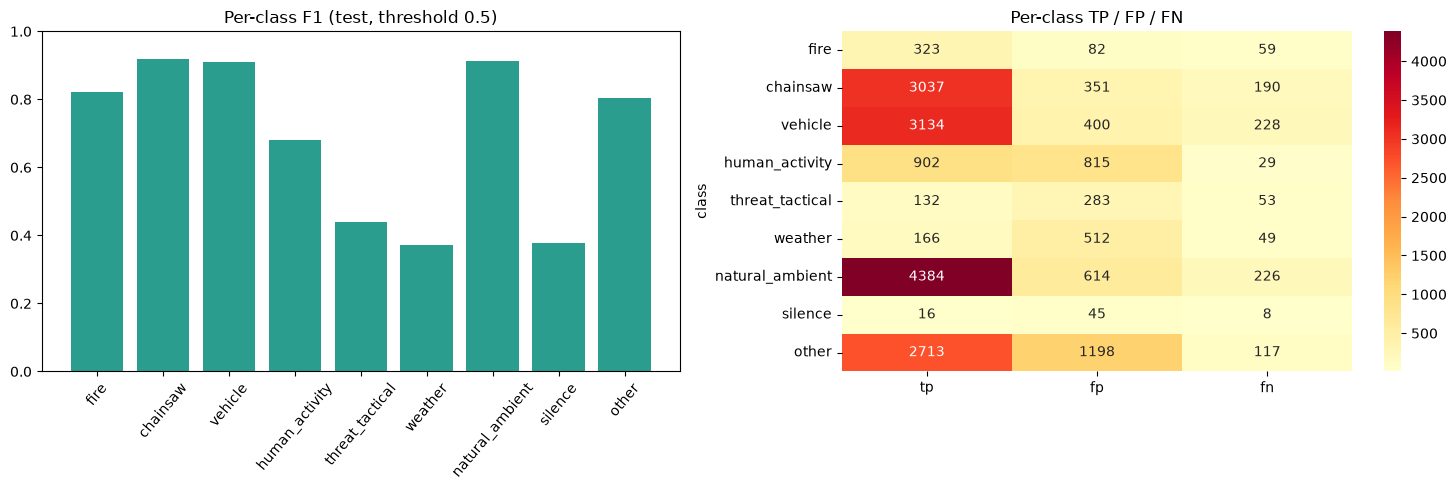

,dataset,n_test_clips,macro_f1,micro_f1,exact_match
5,rfcx_frugalai,7546,0.2069,0.9303,0.8851
0,datasec_v2,3580,0.4712,0.8269,0.7327
6,vehicle_sounds,2846,0.1097,0.9236,0.8749
1,esc50,616,0.3161,0.4526,0.1558
4,fsc22,616,0.3934,0.4041,0.0860
3,footstep_set,354,0.1105,0.8403,0.6864
2,fire_google_drive,208,0.1111,0.9607,0.9183


Test clips with at least one false positive/negative: 3391


,dataset,true_labels,predicted_labels,false_negative_labels,false_positive_labels,label_error_count,processed_file,source_file
12505,fsc22,[silence],"[human_activity, threat_tactical, weather, nat...",[silence],"[human_activity, threat_tactical, weather, nat...",6,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
12539,fsc22,[silence],"[human_activity, threat_tactical, weather, nat...",[silence],"[human_activity, threat_tactical, weather, nat...",6,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
3617,datasec_v2,[fire],"[human_activity, threat_tactical, weather, other]",[fire],"[human_activity, threat_tactical, weather, other]",5,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
12311,fsc22,[chainsaw],"[human_activity, threat_tactical, weather, other]",[chainsaw],"[human_activity, threat_tactical, weather, other]",5,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
12633,fsc22,[fire],"[human_activity, threat_tactical, weather, other]",[fire],"[human_activity, threat_tactical, weather, other]",5,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
615,esc50,[vehicle],"[human_activity, threat_tactical, weather, other]",[vehicle],"[human_activity, threat_tactical, weather, other]",5,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
12503,fsc22,[fire],"[human_activity, threat_tactical, weather, other]",[fire],"[human_activity, threat_tactical, weather, other]",5,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
417,esc50,[natural_ambient],"[human_activity, threat_tactical, weather, other]",[natural_ambient],"[human_activity, threat_tactical, weather, other]",5,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
469,esc50,[other],"[fire, human_activity, threat_tactical, weather]",[other],"[fire, human_activity, threat_tactical, weather]",5,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...
12357,fsc22,[fire],"[human_activity, threat_tactical, weather, nat...",[fire],"[human_activity, threat_tactical, weather, nat...",5,/Users/guidegiegg/Projects/RakForest-ML/data/p...,/Users/guidegiegg/Projects/RakForest-ML/data/r...


In [6]:
from sklearn.metrics import precision_recall_fscore_support, f1_score, accuracy_score, hamming_loss, average_precision_score

per_class=[]
for i,name in enumerate(class_order):
    precision,recall,f1,support=precision_recall_fscore_support(y_true[:,i],y_pred[:,i],average='binary',zero_division=0)
    try: ap=float(average_precision_score(y_true[:,i],probabilities[:,i])) if y_true[:,i].sum()>0 else float('nan')
    except Exception: ap=float('nan')
    per_class.append({'class':name,'precision':float(precision),'recall':float(recall),'f1':float(f1),'support':int(y_true[:,i].sum()),'average_precision':ap,'tp':int(((y_true[:,i]==1)&(y_pred[:,i]==1)).sum()),'fp':int(((y_true[:,i]==0)&(y_pred[:,i]==1)).sum()),'fn':int(((y_true[:,i]==1)&(y_pred[:,i]==0)).sum())})
per_class_df=pd.DataFrame(per_class)
macro_f1=float(f1_score(y_true,y_pred,average='macro',zero_division=0))
micro_f1=float(f1_score(y_true,y_pred,average='micro',zero_division=0))
subset_accuracy=float(accuracy_score(y_true,y_pred))
hamming=float(hamming_loss(y_true,y_pred))
print(f'Test macro-F1: {macro_f1:.4f} | micro-F1: {micro_f1:.4f} | exact-match: {subset_accuracy:.4f} | Hamming loss: {hamming:.4f} | threshold: {THRESHOLD:.2f}')
display(per_class_df.round(4))

pred_df=test_df.copy()
pred_df['true_labels']=[[class_order[j] for j in np.where(row==1)[0]] for row in y_true]
pred_df['predicted_labels']=[[class_order[j] for j in np.where(row==1)[0]] for row in y_pred]
pred_df['false_negative_labels']=[[class_order[j] for j in np.where((y_true[r]==1)&(y_pred[r]==0))[0]] for r in range(len(y_true))]
pred_df['false_positive_labels']=[[class_order[j] for j in np.where((y_true[r]==0)&(y_pred[r]==1))[0]] for r in range(len(y_true))]
pred_df['max_score']=probabilities.max(axis=1)
pred_df['label_error_count']=[len(a)+len(b) for a,b in zip(pred_df.false_negative_labels,pred_df.false_positive_labels)]
for i,name in enumerate(class_order): pred_df[f'prob_{name}']=probabilities[:,i]
print('Test support per class:'); display(per_class_df.set_index('class')[['support','tp','fp','fn']])
fig,axes=plt.subplots(1,2,figsize=(15,5))
axes[0].bar(per_class_df['class'],per_class_df['f1'],color='#2a9d8f'); axes[0].set_title('Per-class F1 (test, threshold 0.5)'); axes[0].set_ylim(0,1); axes[0].tick_params(axis='x',rotation=50)
confusion_counts=per_class_df.set_index('class')[['tp','fp','fn']]
sns.heatmap(confusion_counts,annot=True,fmt='d',cmap='YlOrRd',ax=axes[1]); axes[1].set_title('Per-class TP / FP / FN')
plt.tight_layout(); plt.show()

per_dataset=[]
for dataset,g in pred_df.groupby('dataset'):
    indices=g.index.to_numpy()
    yt=y_true[indices]; yp=y_pred[indices]
    per_dataset.append({'dataset':dataset,'n_test_clips':len(g),'macro_f1':float(f1_score(yt,yp,average='macro',zero_division=0)),'micro_f1':float(f1_score(yt,yp,average='micro',zero_division=0)),'exact_match':float(accuracy_score(yt,yp))})
per_dataset_df=pd.DataFrame(per_dataset).sort_values('n_test_clips',ascending=False)
display(per_dataset_df.round(4))
errors=pred_df[pred_df.label_error_count.gt(0)].sort_values(['label_error_count','max_score'],ascending=[False,False])
print('Test clips with at least one false positive/negative:',len(errors))
display(errors[['dataset','true_labels','predicted_labels','false_negative_labels','false_positive_labels','label_error_count','processed_file','source_file']].head(50))


## 7. ฟังตัวอย่างที่โมเดลทายผิดและบันทึกผล

In [7]:
predictions_path=REPORT_DIR/'multilabel_test_predictions.parquet'
pred_df.to_parquet(predictions_path,index=False)
metrics={'checkpoint':str(CHECKPOINT_PATH.relative_to(PROJECT_ROOT)),'schema_version':'multilabel-v1','test_rows':len(test_df),'test_groups':int(test_df.group_key.nunique()),'macro_f1':macro_f1,'micro_f1':micro_f1,'exact_match':subset_accuracy,'hamming_loss':hamming,'threshold':THRESHOLD,'naturally_co_labeled_test_clips':co_labeled,'class_names':class_order,'test_split_used_for_selection':False}
metrics_path=REPORT_DIR/'multilabel_test_metrics.json'; metrics_path.write_text(json.dumps(metrics,indent=2,ensure_ascii=False))
per_class_df.to_csv(REPORT_DIR/'multilabel_test_metrics_by_class.csv',index=False)
per_dataset_df.to_csv(REPORT_DIR/'multilabel_test_metrics_by_dataset.csv',index=False)
print('Saved predictions:',predictions_path)
print('Saved metrics:',metrics_path)
print('Saved per-class metrics:',REPORT_DIR/'multilabel_test_metrics_by_class.csv')


Saved predictions: /Users/guidegiegg/Projects/RakForest-ML/reports/multilabel_test_predictions.parquet
Saved metrics: /Users/guidegiegg/Projects/RakForest-ML/reports/multilabel_test_metrics.json
Saved per-class metrics: /Users/guidegiegg/Projects/RakForest-ML/reports/multilabel_test_metrics_by_class.csv


In [8]:
ERROR_PREVIEW_LIMIT=5
for row in errors.head(ERROR_PREVIEW_LIMIT).itertuples():
    display(Markdown(f"### {row.dataset} | true: **{row.true_labels}** | predicted: **{row.predicted_labels}** | FN: {row.false_negative_labels} | FP: {row.false_positive_labels}"))
    try:
        y,sr=sf.read(row.processed_file,dtype='float32')
        if y.ndim==2: y=y.mean(axis=1)
        display(Audio(y,rate=sr))
    except Exception as e: print(f'Could not play {row.processed_file}: {type(e).__name__}: {e}')


### fsc22 | true: **['silence']** | predicted: **['human_activity', 'threat_tactical', 'weather', 'natural_ambient', 'other']** | FN: ['silence'] | FP: ['human_activity', 'threat_tactical', 'weather', 'natural_ambient', 'other']

### fsc22 | true: **['silence']** | predicted: **['human_activity', 'threat_tactical', 'weather', 'natural_ambient', 'other']** | FN: ['silence'] | FP: ['human_activity', 'threat_tactical', 'weather', 'natural_ambient', 'other']

### datasec_v2 | true: **['fire']** | predicted: **['human_activity', 'threat_tactical', 'weather', 'other']** | FN: ['fire'] | FP: ['human_activity', 'threat_tactical', 'weather', 'other']

### fsc22 | true: **['chainsaw']** | predicted: **['human_activity', 'threat_tactical', 'weather', 'other']** | FN: ['chainsaw'] | FP: ['human_activity', 'threat_tactical', 'weather', 'other']

### fsc22 | true: **['fire']** | predicted: **['human_activity', 'threat_tactical', 'weather', 'other']** | FN: ['fire'] | FP: ['human_activity', 'threat_tactical', 'weather', 'other']

## Outputs และข้อจำกัด
- `reports/multilabel_test_metrics.json` — macro/micro-F1, exact match, Hamming loss และ threshold
- `reports/multilabel_test_metrics_by_class.csv` — precision, recall, F1 และ TP/FP/FN แยกคลาส
- `reports/multilabel_test_metrics_by_dataset.csv` — ผลแยก dataset
- `reports/multilabel_test_predictions.parquet` — labels จริง/ทำนายและ scores รายคลิป

Test ใช้เพื่อรายงานผลเท่านั้น. ถ้าผลไม่ดี อย่าปรับ threshold โดยดู test แล้วรายงานคะแนนชุดเดิมซ้ำ; ใช้ validation หรือเก็บ hold-out ชุดใหม่.